## 2ème PARTIE

## III. Réverification des dimensisons et du nombre des images par classe

## III.1. Chargement des données

In [4]:
import os
from os import *
def get_image_paths(parent_directory, image_extensions=['.jpg', '.jpeg', '.png', '.gif']):
    image_paths = []

    for root, dirs, files in os.walk(parent_directory):
        for file in files:
            if any(file.lower().endswith(ext) for ext in image_extensions):
                image_paths.append(os.path.join(root, file))

    return image_paths

# Replace 'your_parent_directory' with the actual path of your parent directory



In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
indian_coins_directory_1 = '/content/drive/MyDrive/Images_classification/train/rupee_1/'
indian_coins_image_paths_1 = get_image_paths(indian_coins_directory_1, image_extensions=['.jpg'])

indian_coins_directory_2 = '/content/drive/MyDrive/Images_classification/train/rupee_2/'
indian_coins_image_paths_2 = get_image_paths(indian_coins_directory_2, image_extensions=['.jpg'])

indian_coins_directory_5 = '/content/drive/MyDrive/Images_classification/train/rupee_5/'
indian_coins_image_paths_5 = get_image_paths(indian_coins_directory_5, image_extensions=['.jpg'])

indian_coins_directory_10 = '/content/drive/MyDrive/Images_classification/train/rupee_10/'
indian_coins_image_paths_10 = get_image_paths(indian_coins_directory_10, image_extensions=['.jpg'])

## III.2. Vérification des dimensions et du nombre d'images par classe

In [7]:
from PIL import Image

def get_image_dimensions(image_path):
    with Image.open(image_path) as img:
        width, height = img.size
    return width, height

In [8]:
import random
value = random.randint(1, 50)
image_path = indian_coins_image_paths_1[value]
width, height = get_image_dimensions(image_path)
print(f"Image Width: {width} pixels")
print(f"Image Height: {height} pixels")
print(f"length of dataset : {len(indian_coins_image_paths_1)} images")

Image Width: 5184 pixels
Image Height: 3888 pixels
length of dataset : 133 images


In [9]:
import random
value = random.randint(1, 50)
image_path = indian_coins_image_paths_2[value]
width, height = get_image_dimensions(image_path)
print(f"Image Width: {width} pixels")
print(f"Image Height: {height} pixels")
print(f"length of dataset : {len(indian_coins_image_paths_2)} images")

Image Width: 5184 pixels
Image Height: 3888 pixels
length of dataset : 133 images


In [10]:
import random
value = random.randint(1, 50)
image_path = indian_coins_image_paths_5[value]
width, height = get_image_dimensions(image_path)
print(f"Image Width: {width} pixels")
print(f"Image Height: {height} pixels")
print(f"length of dataset : {len(indian_coins_image_paths_5)} images")

Image Width: 5184 pixels
Image Height: 3888 pixels
length of dataset : 133 images


In [11]:
import random
value = random.randint(1, 50)
image_path = indian_coins_image_paths_10[value]
width, height = get_image_dimensions(image_path)
print(f"Image Width: {width} pixels")
print(f"Image Height: {height} pixels")
print(f"length of dataset : {len(indian_coins_image_paths_10)} images")

Image Width: 5184 pixels
Image Height: 3888 pixels
length of dataset : 133 images


In [44]:
import numpy as np
image_array = np.array(Image.open(indian_coins_image_paths_1[0]))

max_pixel_value = np.amax(image_array)

min_pixel_value = np.amin(image_array)

print(f"Valeur maximale du pixel dans l'image: {max_pixel_value}")
print(f"Valeur minimale du pixel dans l'image: {min_pixel_value}")

Valeur maximale du pixel dans l'image: 255
Valeur minimale du pixel dans l'image: 0


## IV. Prétraitement des données

## IV.1 Division des données en données d'entrainement, de validation, de test

In [13]:
import shutil

def copy_image(source_path, destination_path):
    try:
        shutil.copy2(source_path, destination_path)
        print("Image copied successfully!")
    except FileNotFoundError:
        print(f"Error: Source image file not found at {source_path}")

def copy_indian(A,B, C, save_path):
    l=C[A:B]
    for i in range(len(l)):
        input_path=l[i]
        image_name = os.path.basename(input_path)
        output_path=save_path+image_name
        copy_image(input_path, output_path)

In [ ]:
copy_indian(0,133, indian_coins_image_paths_1,"/content/drive/MyDrive/Images_classification/train/rupee_1/")

copy_indian(134,172, indian_coins_image_paths_1,"/content/drive/MyDrive/Images_classification/val/rupee_1/")

copy_indian(173,190, indian_coins_image_paths_1,"/content/drive/MyDrive/Images_classification/test/rupee_1/")

In [ ]:
copy_indian(0,133, indian_coins_image_paths_2,"/content/drive/MyDrive/Images_classification/train/rupee_2/")

copy_indian(134,172, indian_coins_image_paths_2,"/content/drive/MyDrive/Images_classification/val/rupee_2/")

copy_indian(173,190, indian_coins_image_paths_2,"/content/drive/MyDrive/Images_classification/test/rupee_2/")

In [ ]:
copy_indian(0,133, indian_coins_image_paths_5,"/content/drive/MyDrive/Images_classification/train/rupee_5/")

copy_indian(134,172, indian_coins_image_paths_5,"/content/drive/MyDrive/Images_classification/val/rupee_5/")

copy_indian(173,190, indian_coins_image_paths_5,"/content/drive/MyDrive/Images_classification/test/rupee_5/")

In [ ]:
copy_indian(0,133, indian_coins_image_paths_10,"/content/drive/MyDrive/Images_classification/train/rupee_10/")

copy_indian(134,172, indian_coins_image_paths_10,"/content/drive/MyDrive/Images_classification/val/rupee_10/")

copy_indian(173,190, indian_coins_image_paths_10,"/content/drive/MyDrive/Images_classification/test/rupee_10/")

In [ ]:
pip install -U tensorboard_plugin_profile

In [16]:
IMG_SIZE=[224,224]
train_path="/content/drive/MyDrive/Images_classification/train"
val_path="/content/drive/MyDrive/Images_classification/val"
test_path="/content/drive/MyDrive/Images_classification/test"

## IV.2 Rédimensionnement des images

In [17]:
import tensorflow as tf
def resize_and_rescale(image):
  image = tf.cast(image, tf.float32)
  image = tf.image.resize(image, [IMG_SIZE[0], IMG_SIZE[1]])
  image = (image / 255.0)
  return image

In [18]:
def augment(image):
  image = tf.image.random_flip_left_right(image)
  image = tf.image.resize_with_crop_or_pad(image,IMG_SIZE[0]+6, IMG_SIZE[1]+6)
  image = tf.image.random_crop(image,size=[IMG_SIZE[0],IMG_SIZE[1],3])
  image = tf.image.random_brightness(image,max_delta = 0.2)
  image = tf.image.adjust_hue(image, 0.04, name=None)
  image = resize_and_rescale(image)

  return image

In [19]:
train_datagen = ImageDataGenerator(
                                  preprocessing_function=augment
                                   )

val_datagen = ImageDataGenerator(
                                 preprocessing_function=resize_and_rescale,
                                 )

test_datagen = ImageDataGenerator(
                                 preprocessing_function=resize_and_rescale,
                                 )

In [20]:
training_set = train_datagen.flow_from_directory(train_path,
                                                 target_size=(224,224),

                                                 batch_size = 10,
                                                 class_mode = 'categorical'

                                                )
val_set = val_datagen.flow_from_directory(val_path,
                                            target_size=(224,224),
                                            batch_size = 10,
                                            class_mode = 'categorical'
                                          )

test_set = test_datagen.flow_from_directory(test_path,
                                            target_size=(224,224),
                                            batch_size = 10,
                                            class_mode = 'categorical'

                                            )

Found 532 images belonging to 4 classes.
Found 152 images belonging to 4 classes.
Found 68 images belonging to 4 classes.


## V.1 Implémentation de l'architecture du modèle

In [21]:
import sys
import os
import shutil

import numpy as np
import matplotlib.pyplot as plt
import cv2
import pandas as pd
import tensorflow as tf

from PIL import Image
from google.colab.patches import cv2_imshow

from tensorflow.keras import layers,models
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow import keras

from keras.preprocessing.image import load_img
from keras.preprocessing.image import img_to_array

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score

In [22]:
!pip install -q -U keras-tuner

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 128.9/128.9 kB 2.0 MB/s eta 0:00:00


In [23]:
import keras_tuner as kt
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.models import Model

In [24]:
model = VGG16(input_shape=IMG_SIZE + [3], weights='imagenet', include_top=False)
model.trainable = False

58889256/58889256 [==============================] - 1s 0us/step


In [25]:
for layer in model.layers:
  layer.trainable = False
x = Flatten()(model.output) #Output obtained on vgg16 is now flattened.
prediction = Dense(4, activation='softmax')(x)
model = Model(inputs=model.input, outputs=prediction)
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0     

In [ ]:
!pip install tensorflow-addons

## V.2 Entrainement et évaluation des performances du modèle

In [ ]:
from tensorflow.keras.metrics import categorical_accuracy, AUC, Precision
from tensorflow_addons.metrics import F1Score

recall = keras.metrics.Recall(name='recall')
f1_score = F1Score(num_classes=4)

METRICS = keras.metrics.Precision(name='precision')
keras.metrics.Recall(name='recall')

model.compile(tf.keras.optimizers.Adam(learning_rate=0.0003),
             loss= tf.keras.losses.CategoricalCrossentropy(from_logits=False),
             metrics=[METRICS, recall, f1_score, categorical_accuracy])

In [28]:
stop_early=EarlyStopping(monitor='f1_score',verbose=1,patience=5,restore_best_weights=True)
reduce_lr=tf.keras.callbacks.ReduceLROnPlateau(
          monitor="f1_score",factor=0.5, patience=3, verbose=1)

In [29]:
STEP_SIZE_TRAIN=20
STEP_SIZE_VALID=10

In [31]:
# fit the model
history = model.fit(
  training_set,
  validation_data=val_set,
  epochs=20,
  steps_per_epoch = STEP_SIZE_TRAIN,
  validation_steps = STEP_SIZE_VALID
  )

Epoch 1/20
20/20 [==============================] - 214s 11s/step - loss: 1.4571 - precision: 0.3387 - recall: 0.1050 - f1_score: 0.3304 - categorical_accuracy: 0.3350 - val_loss: 1.2651 - val_precision: 0.9000 - val_recall: 0.0900 - val_f1_score: 0.3940 - val_categorical_accuracy: 0.4600
Epoch 2/20
20/20 [==============================] - 115s 6s/step - loss: 1.1305 - precision: 0.7222 - recall: 0.2600 - f1_score: 0.4483 - categorical_accuracy: 0.4550 - val_loss: 0.9980 - val_precision: 0.8261 - val_recall: 0.3800 - val_f1_score: 0.3802 - val_categorical_accuracy: 0.4800
Epoch 3/20
20/20 [==============================] - 95s 5s/step - loss: 0.9692 - precision: 0.7727 - recall: 0.4250 - f1_score: 0.6289 - categorical_accuracy: 0.6400 - val_loss: 0.8941 - val_precision: 0.7931 - val_recall: 0.4600 - val_f1_score: 0.4764 - val_categorical_accuracy: 0.5600
Epoch 4/20
20/20 [==============================] - 86s 4s/step - loss: 0.7756 - precision: 0.9107 - recall: 0.5100 - f1_score: 0.710

## Evaluation des performances du modèle par des graphes et la matrice de confusion

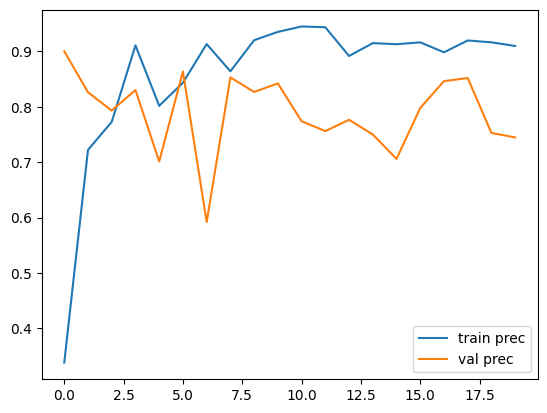

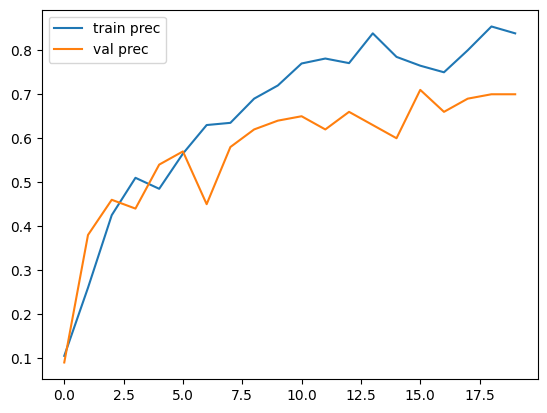

In [32]:
# prec
plt.plot(history.history['precision'], label='train prec')
plt.plot(history.history['val_precision'], label='val prec')
plt.legend()
#plt.savefig('vgg-loss-rps-1.png')
plt.show()

# prec
plt.plot(history.history['recall'], label='train prec')
plt.plot(history.history['val_recall'], label='val prec')
plt.legend()
#plt.savefig('vgg-loss-rps-1.png')
plt.show()



7/7 [==============================] - 51s 8s/step
Confusion Matrix
Classification_report
              precision    recall  f1-score   support

     rupee_1       0.00      0.00      0.00        17
    rupee_10       0.00      0.00      0.00        17
     rupee_2       0.42      0.47      0.44        17
     rupee_5       0.17      0.35      0.23        17

    accuracy                           0.21        68
   macro avg       0.15      0.21      0.17        68
weighted avg       0.15      0.21      0.17        68

Accuracy_score: 0.20588235294117646
Balanced Accuracy Score: 0.20588235294117646


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


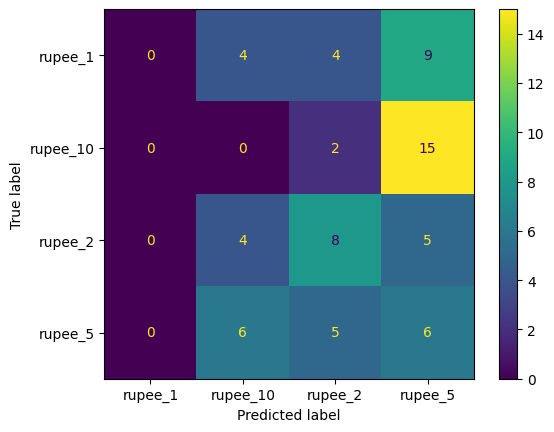

In [33]:
Y_pred = model.predict(test_set)
y_pred = np.argmax(Y_pred,axis=1)
target_names = list(test_set.class_indices.keys())
y_true = test_set.classes

print('Confusion Matrix')
imbalanced_cm = confusion_matrix(y_true,y_pred)
ConfusionMatrixDisplay(imbalanced_cm, display_labels=target_names).plot(values_format="d")

print('Classification_report')
print(classification_report(y_true,y_pred,target_names=target_names))

print(f'Accuracy_score: {accuracy_score(y_true, y_pred)}')
print(f"Balanced Accuracy Score: {balanced_accuracy_score(y_true, y_pred)}")

In [34]:
model.evaluate(val_set)

16/16 [==============================] - 29s 2s/step - loss: 0.9129 - precision: 0.7500 - recall: 0.7105 - f1_score: 0.6479 - categorical_accuracy: 0.7368


[0.912946879863739,
 0.75,
 0.7105262875556946,
 array([0.05128205, 0.987013  , 0.7659574 , 0.78723407], dtype=float32),
 0.7368420958518982]

## VI. Faire une prédiction

In [39]:
from keras.preprocessing import image

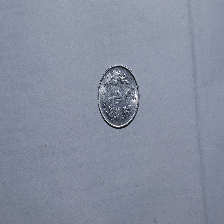

In [41]:
#Load flower jpeg image from local and set target size to 224 x 224
img = image.load_img('/content/drive/MyDrive/Images_classification/test/rupee_1/rupee1_177.JPG', target_size=(224,224))
img



In [42]:
# Get class names
class_names =list(test_set.class_indices.keys())
print('Class names: ', class_names)

#convert image to array
input_img = image.img_to_array(img)
input_img = np.expand_dims(input_img, axis=0)
input_img

preditcion = model.predict(input_img)
print('Prediction: ', preditcion)

predicted_class = np.argmax(preditcion)
print('Predicted class: ', class_names[predicted_class])

Class names:  ['rupee_1', 'rupee_10', 'rupee_2', 'rupee_5']
1/1 [==============================] - 0s 18ms/step
Prediction:  [[5.3537594e-38 0.0000000e+00 0.0000000e+00 1.0000000e+00]]
Predicted class:  rupee_5


## Observations


*   Le modèle présente de bonnes performance en terme de précision pour l'ensemble d'entrainement et moins pour la validation ce qui est confirmé par la matrice de confusion où les prédictions des classes de 1 et 10 roupies sont nulles et les autres classes n'atteignent pas 0.5
*   L'exemple montre une prédiction biaisée. Cela semble être dû à la qualité des images; il aurait fallu des images plus zoomées,nettes.
Nous ne continuerons donc pas avec ce modèle et ce dataset pour le développement de l'interface (nous ne sauvegardons donc pas le modèle)

